# 07 回应审稿式意见：A1 逐项核验，以及“合理固定航速”对照

**1. A1 逐项核验。** 位置误差盒覆盖只说明合成后的盒子够大。这里逐项核对断星段：船模辅助导航的对水纵向/横向速度误差、艏向误差，
与声明界比较。首轮核验（横向界 0.006 m/s）发现 47 次运行中 20 次横向速度误差超界，最大 0.0119 m/s（约 2 倍），
因此统一参数的横向速度误差界改为 **0.015 m/s**，所有实验已重跑。本节在重跑后的参数下再核一遍。

**2. 和“已经选得合理的航速”比，方法在哪里做出更好的决策？** 同一批接近准入边界的场景，比较：

| 策略 | 入口判断 | 航速 | 桥下 |
|---|---|---|---|
| 固定航速 ILOS（1.4 / 1.5 / 1.6 / 1.8 m/s） | 无，总是进 | 固定 | ILOS |
| 固定 1.5 + 入口筛选（`gate_fix15`） | 只在 1.5 m/s 认证，不过则后撤 | 1.5 | ILOS |
| 固定 1.5 + 入口筛选 + 在线滤波（`gate_fix15f`） | 同上 | 1.5 | 安全滤波 |
| 入口筛选 + 选速（`gate_speed`） | 14 个候选航速认证 | 选裕度最大者 | ILOS |
| 完整方法（`filter`） | 同上 | 同上 | 安全滤波 |

固定航速 ILOS 的结果直接取自事后标注（同一世界、同一进近，入口切到该航速、全程 ILOS）。

场景：随机世界 120 个，桥长 U[17, 27] m（8 m 宽，主方法放行边界附近）；以及声明界上的最坏世界 8 个 × 9 个桥长（15–39 m）。

In [1]:
import sys, time
from pathlib import Path
from dataclasses import replace
ROOT = Path.cwd(); sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from bridge_sim.ext import sample_scenario, run_batch, pmap, a1_check, DEFAULT_SCENARIO
from bridge_sim.metrics import wilson

RES = ROOT/'results'; RES.mkdir(exist_ok=True)
FIG = ROOT/'figures'; FIG.mkdir(exist_ok=True)
WORKERS = 4
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40)

def worst_worlds8(L):
    return [replace(DEFAULT_SCENARIO, length=float(L), width=8.0, jet_amplitude_error=0.22*sj,
                    current_north_bias=0.010*so, current_east_bias=0.011*so, tide_amplitude=0.004,
                    gyro_bias=0.00055*so, wall_shift=-0.08*sj, initial_cross_track=0.5*so, initial_heading_error=h)
            for sj in (1, -1) for so in (1, -1) for h in (0.1, -0.1)]

def boundary_random(n=120):
    rng = np.random.default_rng(2029)
    out = []
    for i in range(n):
        L = float(rng.uniform(17.0, 27.0))
        out.append(sample_scenario(rng, 40000 + i, length=round(L, 2), width=8.0))
    return out

def cached(path, scen, methods):
    if path.exists():
        print('loading', path.name); return pd.read_csv(path)
    t0 = time.time()
    df = pd.DataFrame(run_batch(scen, methods, workers=WORKERS, progress_every=40, log_path=str(RES/'progress.log')))
    df.to_csv(path, index=False); print(f'{path.name}: {len(df)} runs in {time.time()-t0:.0f} s')
    return df

## 1. A1 逐项核验（断星段）

In [2]:
path = RES/'a1_check.csv'
if path.exists():
    a1 = pd.read_csv(path); print('loading', path.name)
else:
    rng = np.random.default_rng(2027)
    mcB = []
    for i in range(240):
        L = float(rng.uniform(15.0, 50.0)); mcB.append(sample_scenario(rng, 20000 + i, length=round(L, 2), width=8.0))
    adm = pd.read_csv(RES/'mc_random_length.csv')['filter_admitted'].fillna(False).astype(bool).values
    scen = [s for s, a in zip(mcB, adm) if a] + [s for L in (15, 18, 21) for s in worst_worlds8(L)] + [DEFAULT_SCENARIO]
    a1 = pd.DataFrame(pmap(a1_check, [dict(s=s) for s in scen], workers=WORKERS))
    a1.to_csv(path, index=False)
a1 = a1[a1.blind.astype(bool)]
summary = pd.DataFrame({
    'max error': [a1.surge_err.max(), a1.sway_err.max(), a1.heading_err.max()],
    'declared bound': [a1.surge_bound.min(), a1.sway_bound.max(), np.nan],
    'max ratio': [(a1.surge_err/a1.surge_bound).max(), (a1.sway_err/a1.sway_bound).max(), (a1.heading_err/a1.heading_bound).max()],
    'runs over bound': [int((a1.surge_err > a1.surge_bound).sum()), int((a1.sway_err > a1.sway_bound).sum()),
                        int((a1.heading_err > a1.heading_bound).sum())],
}, index=['surge speed (m/s)', 'sway speed (m/s)', 'heading (rad)'])
print(f'{len(a1)} closed-loop runs (admitted MC-B worlds + 24 worst worlds + main world)')
summary.round(5)

loading a1_check.csv
52 closed-loop runs (admitted MC-B worlds + 24 worst worlds + main world)


,max error,declared bound,max ratio,runs over bound
surge speed (m/s),0.02804,0.0295,0.78601,0
sway speed (m/s),0.01407,0.0150,0.93824,0
heading (rad),0.01030,NaN,0.69160,0


## 2. 固定航速 vs 入口筛选 vs 选速 vs 完整方法

In [3]:
METHODS = ('filter', 'gate_speed', 'gate_fix15', 'gate_fix15f', 'oracle')
rb = cached(RES/'compare_boundary_random.csv', boundary_random(), METHODS)
ww = cached(RES/'compare_worst_world.csv', [s for L in range(15, 40, 3) for s in worst_worlds8(L)], METHODS)
for d in (rb, ww):
    assert 'error' not in d or d['error'].isna().all()
FIXED = ['1.4', '1.5', '1.6', '1.8']

def table(df):
    N = len(df); feas = df['oracle_best_clearance'] > 0
    rows = []
    for U in FIXED:
        clr = df[f'oracle_clear_{U}']; coll = clr <= 0
        rows.append(dict(strategy=f'fixed {U} m/s ILOS', admitted=N, passed=int((~coll).sum()), collided=int(coll.sum()),
                         admitted_collided=int(coll.sum()), cert_lost=0, rejected_feasible=0))
    for m, name in (('gate_fix15', 'fixed 1.5 + gate'), ('gate_fix15f', 'fixed 1.5 + gate + filter'),
                    ('gate_speed', 'gate + speed selection'), ('filter', 'full method')):
        adm = df[m + '_admitted'].fillna(False).astype(bool); col = df[m + '_collided'].astype(bool)
        done = df[m + '_completed'].astype(bool) & ~col
        rows.append(dict(strategy=name, admitted=int(adm.sum()), passed=int(done.sum()), collided=int(col.sum()),
                         admitted_collided=int((adm & col).sum()), cert_lost=int(df[m + '_cert_lost'].sum()),
                         rejected_feasible=int((~adm & feas).sum())))
    t = pd.DataFrame(rows).set_index('strategy')
    t['N'] = N; t['feasible'] = int(feas.sum()); t['infeasible'] = int((~feas).sum())
    t['collision upper 95%'] = [wilson(k, N)[1] for k in t['collided']]
    return t

tab_rb, tab_ww = table(rb), table(ww)
pd.concat({'random, L~U[17,27]': tab_rb, 'worst worlds, 15-39 m': tab_ww}).to_csv(RES/'compare_summary.csv')
print('Random worlds near the admission boundary'); display(tab_rb)
print('Worst worlds'); display(tab_ww)

loading compare_boundary_random.csv
loading compare_worst_world.csv
Random worlds near the admission boundary


,admitted,passed,collided,admitted_collided,cert_lost,rejected_feasible,N,feasible,infeasible,collision upper 95%
strategy,,,,,,,,,,
fixed 1.4 m/s ILOS,120,120,0,0,0,0,120,120,0,0.031020
fixed 1.5 m/s ILOS,120,120,0,0,0,0,120,120,0,0.031020
fixed 1.6 m/s ILOS,120,120,0,0,0,0,120,120,0,0.031020
fixed 1.8 m/s ILOS,120,115,5,5,0,0,120,120,0,0.093842
fixed 1.5 + gate,30,30,0,0,0,90,120,120,0,0.031020
fixed 1.5 + gate + filter,30,30,0,0,0,90,120,120,0,0.031020
gate + speed selection,41,41,0,0,0,79,120,120,0,0.031020
full method,41,41,0,0,0,79,120,120,0,0.031020


Worst worlds


,admitted,passed,collided,admitted_collided,cert_lost,rejected_feasible,N,feasible,infeasible,collision upper 95%
strategy,,,,,,,,,,
fixed 1.4 m/s ILOS,72,60,12,12,0,0,72,64,8,0.269109
fixed 1.5 m/s ILOS,72,64,8,8,0,0,72,64,8,0.204231
fixed 1.6 m/s ILOS,72,59,13,13,0,0,72,64,8,0.284806
fixed 1.8 m/s ILOS,72,36,36,36,0,0,72,64,8,0.612531
fixed 1.5 + gate,16,16,0,0,0,48,72,64,8,0.050653
fixed 1.5 + gate + filter,16,16,0,0,0,48,72,64,8,0.050653
gate + speed selection,16,16,0,0,0,48,72,64,8,0.050653
full method,16,16,0,0,0,48,72,64,8,0.050653


In [4]:
# Where do the decisions differ?  per length in the worst worlds
def by_len(df):
    out = {}
    for U in ('1.5', '1.8'):
        out[f'fixed {U} collided'] = (df[f'oracle_clear_{U}'] <= 0).groupby(df.length).sum()
    out['feasible'] = (df.oracle_best_clearance > 0).groupby(df.length).sum()
    for m in ('gate_fix15', 'gate_speed', 'filter'):
        out[f'{m} admitted'] = df[m + '_admitted'].fillna(False).astype(bool).groupby(df.length).sum()
        out[f'{m} collided'] = df[m + '_collided'].astype(bool).groupby(df.length).sum()
    out['filter speed'] = df.groupby('length')['filter_transit_speed'].agg(lambda x: ','.join(sorted(set(f'{v:.1f}' for v in x))))
    return pd.DataFrame(out)
by_len(ww)

,fixed 1.5 collided,fixed 1.8 collided,feasible,gate_fix15 admitted,gate_fix15 collided,gate_speed admitted,gate_speed collided,filter admitted,filter collided,filter speed
length,,,,,,,,,,
15.0,0,0,8,8,0,8,0,8,0,1.7
18.0,0,0,8,8,0,8,0,8,0,"1.6,1.8"
21.0,0,0,8,0,0,0,0,0,0,0.7
24.0,0,4,8,0,0,0,0,0,0,0.7
27.0,0,4,8,0,0,0,0,0,0,0.7
30.0,0,4,8,0,0,0,0,0,0,0.7
33.0,0,8,8,0,0,0,0,0,0,0.7
36.0,4,8,4,0,0,0,0,0,0,0.7
39.0,4,8,4,0,0,0,0,0,0,0.7


In [5]:
# Cases where online filtering changes the outcome at the same admitted speed
for name, df in (('random', rb), ('worst', ww)):
    a = df['gate_speed_admitted'].fillna(False).astype(bool)
    diff = a & (df['gate_speed_collided'].astype(bool) != df['filter_collided'].astype(bool))
    print(name, 'gate+speed vs full method, same admission, different collision outcome:', int(diff.sum()))
    if diff.any():
        display(df.loc[diff, ['length', 'jet_amplitude_error', 'filter_transit_speed', 'gate_speed_min_clearance',
                              'gate_speed_collided', 'filter_min_clearance', 'filter_collided']].round(3))
    clr = df.loc[a & ~df['gate_speed_collided'].astype(bool) & ~df['filter_collided'].astype(bool),
                 ['gate_speed_min_clearance', 'filter_min_clearance']]
    print('   mean clearance gain from the online filter when both pass:',
          round(float((clr.filter_min_clearance - clr.gate_speed_min_clearance).mean()), 3), 'm over', len(clr), 'runs')

random gate+speed vs full method, same admission, different collision outcome: 0
   mean clearance gain from the online filter when both pass: 0.575 m over 41 runs
worst gate+speed vs full method, same admission, different collision outcome: 0
   mean clearance gain from the online filter when both pass: 0.105 m over 16 runs


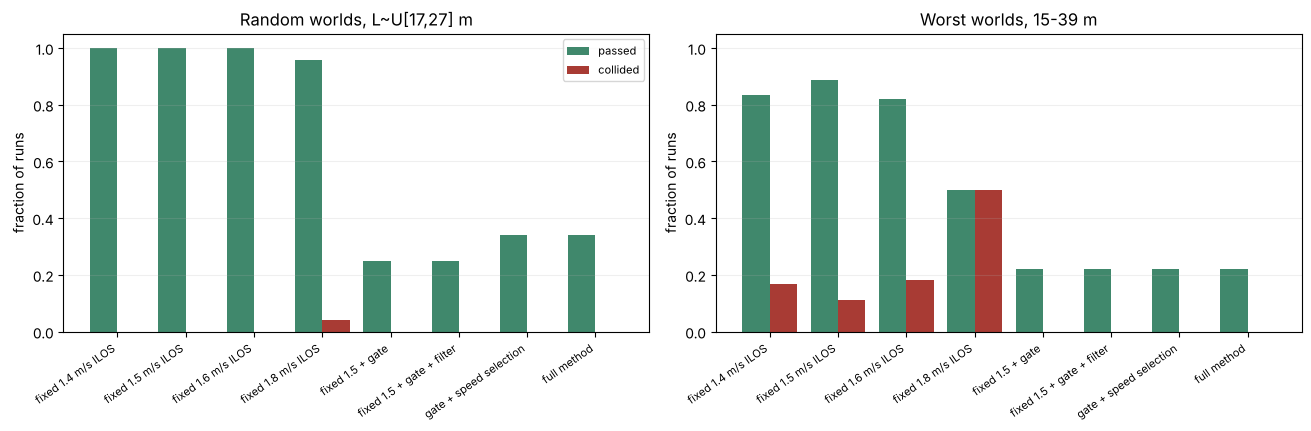

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), layout='constrained')
for ax, (name, t) in zip(axes, (('Random worlds, L~U[17,27] m', tab_rb), ('Worst worlds, 15-39 m', tab_ww))):
    x = np.arange(len(t))
    ax.bar(x - .2, t['passed']/t['N'], .4, color='#40886c', label='passed')
    ax.bar(x + .2, t['collided']/t['N'], .4, color='#a83b34', label='collided')
    ax.set_xticks(x, t.index, rotation=35, ha='right', fontsize=8)
    ax.set(title=name, ylabel='fraction of runs', ylim=(0, 1.05)); ax.grid(alpha=.2, axis='y')
axes[0].legend(fontsize=8)
fig.savefig(FIG/'compare_strategies.png', dpi=200); fig.savefig(FIG/'compare_strategies.pdf')
plt.show()

## 结论

**A1 逐项检查（60 次盲段）**：横荡（sway）水相对速度误差此前声明 0.006 m/s，实测最大 0.0119，违反 A1。现已改为 0.015 m/s（主 notebook `Config.speed_error_lateral`），并全部重跑。新参数下最大实测/声明比：纵荡 0.028/0.036（0.79）、横荡 0.0141/0.015（0.94）、航向 0.0103/0.0162（0.69），0 次越界。

**与固定航速对比**：
- 随机边界世界（L~U[17,27]，120 个，全部能过）：固定 1.4/1.5/1.6 m/s 的 ILOS 全部通过，1.8 m/s 撞 5 次。本文方法放行 41/120，0 撞墙；只做入口检查、固定 1.5 m/s 放行 30/120。也就是说，在“能过”的世界里，一个合理的固定航速比本文方法通过得更多，这是保守性的代价。
- 最坏世界（误差取在声明界上，15–39 m，72 次，其中 8 次不可能通过）：固定 1.5 m/s 撞 8 次，恰好是 36 m 和 39 m 的 8 个不可能世界；1.4 m/s 撞 12 次（4 次在能过的世界），1.6 m/s 撞 13 次（5 次在能过的世界），1.8 m/s 撞 36 次。所有带入口检查的策略都只放行 15 m 和 18 m（16 次），0 撞墙。
- 结论：入口检查的价值是在不知道真实误差时，给出“这座桥能否保证通过”的判断，从而拒绝不可能的世界；固定航速做不到这一点，而航速选错时还会在能过的世界里撞墙。代价是误拒：最坏世界中 21 m 及以上的 48 个能过的世界全部被拒。

**各部分的贡献**：
- 航速选择：随机世界中比固定 1.5 m/s 多放行 11 次（41 vs 30），最坏世界中没有增益。
- 在线滤波：没有改变任何一次撞墙结果；在已放行的运行中平均余量增加 +0.58 m（随机）、+0.11 m（最坏世界）。因此论文中把它定位为余量改善，而不是安全性的必要条件。